In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score
from scipy.optimize import minimize

In [22]:
data = [[ 2.0, 2.2 , 1],
        [2.7 ,2.5 , 1],
        [2.3, 2.0 , 1],
        [3.1, 2.3 , 1],
        [2.5 ,2.4 , 1],
        [2.8 ,2.7 , 1],
        [1.6, 1.5 ,-1],
        [2.0 ,1.9 ,-1],
        [2.1, 1.8 ,-1],
        [1.7, 1.6, -1],
        [1.8 ,1.7 ,-1],
        [2.0, 1.6 ,-1]]

In [23]:
df = pd.DataFrame(data)

In [24]:
df.columns = ["x1", "x2", "y"]

In [25]:
df.head(5)

,x1,x2,y
0,2.0,2.2,1
1,2.7,2.5,1
2,2.3,2.0,1
3,3.1,2.3,1
4,2.5,2.4,1


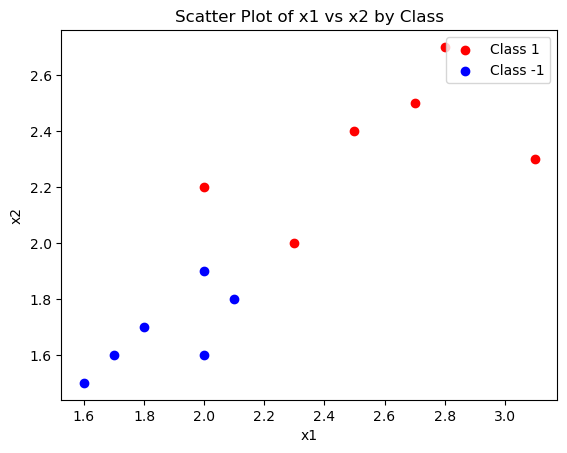

In [26]:
# Plot
plt.scatter(df[df['y'] == 1]['x1'], df[df['y'] == 1]['x2'], color='red', label='Class 1')
plt.scatter(df[df['y'] == -1]['x1'], df[df['y'] == -1]['x2'], color='blue', label='Class -1')

# Add labels and legend
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Scatter Plot of x1 vs x2 by Class')
plt.legend()
plt.show()

In [27]:
X = np.array(df.iloc[:, : -1])
y = np.array(df.iloc[:, -1:])

In [28]:
def learn_svm(X, y):
    N, d = X.shape

    # Define C, c, A, a, B, b
    C = np.outer(y, y) * (X @ X.T)
    C += 1e-8 * np.eye(N)  # Regularization for stability
    c = -np.ones(N)
    A = y.reshape(1, -1)
    a = np.array([0])
    B = -np.eye(N)
    b = np.zeros(N)

    # Compute N+ and N-
    N_plus = np.sum(y == 1)
    N_minus = N - N_plus

    # Initialize alpha
    alpha_init = np.where(y == 1, 1 / N_plus, 1 / N_minus)

    # Quadratic programming solver
    def objective(alpha):
        return 0.5 * alpha @ C @ alpha + c @ alpha

    def equality_constraint(alpha):
        return A @ alpha - a

    constraints = [
        {"type": "eq", "fun": equality_constraint},
        {"type": "ineq", "fun": lambda alpha: alpha}  # Ensure alpha >= 0
    ]

    result = minimize(
        fun=objective,
        x0=alpha_init,
        constraints=constraints,
        method='SLSQP'
    )
    alpha = result.x

    # Compute beta and beta0
    beta = (alpha * y.ravel()) @ X
    support_vectors = np.where(alpha > 1e-5)[0]
    beta_0 = np.mean(y[support_vectors] - X[support_vectors] @ beta)

    return beta_0, beta


In [29]:
beta_0, beta = learn_svm(X, y)
print(f"Beta_0 (bias): {beta_0}")
print(f"Beta (weights): {beta}")

Beta_0 (bias): -22.55561873982946
Beta (weights): [4.44446865 6.66667275]


/var/folders/4m/t9k_jsy176ngtyczt72zczj40000gn/T/ipykernel_53695/1608809079.py:32: DeprecationWarning: Use of `minimize` with `x0.ndim != 1` is deprecated. Currently, singleton dimensions will be removed from `x0`, but an error will be raised in SciPy 1.11.0.
  result = minimize(


In [30]:
# Compute predictions using the SVM model
# Decision boundary: beta_0 + beta[0] * x1 + beta[1] * x2
y_pred = np.sign(beta_0 + X @ beta)

# Compute metrics
accuracy = accuracy_score(y, y_pred)
f1 = f1_score(y, y_pred)
recall = recall_score(y, y_pred)

# Report metrics
print(f"Accuracy: {accuracy:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"Recall: {recall:.2f}")

Accuracy: 1.00
F1 Score: 1.00
Recall: 1.00


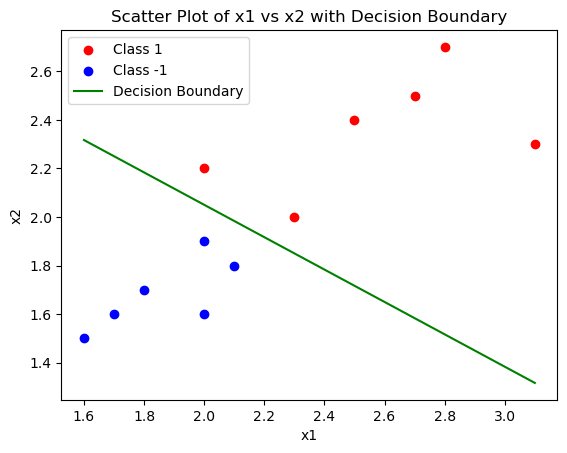

In [31]:
# Plot the data points
plt.scatter(df[df['y'] == 1]['x1'], df[df['y'] == 1]['x2'], color='red', label='Class 1')
plt.scatter(df[df['y'] == -1]['x1'], df[df['y'] == -1]['x2'], color='blue', label='Class -1')

# Compute the decision boundary
x1_vals = np.linspace(df['x1'].min(), df['x1'].max(), 100)
x2_vals = -(beta_0 + beta[0] * x1_vals) / beta[1]
plt.plot(x1_vals, x2_vals, color='green', label='Decision Boundary')

# Add labels and legend
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Scatter Plot of x1 vs x2 with Decision Boundary')
plt.legend()

plt.show()

In [34]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
import torch.optim as optim

#loading the data
c_data = pd.read_csv('creditcard.csv', date_parser='Time')
#viewing the data
c_data.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [35]:
#analysing the data to understand its distribution
c_data.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,3.918649e-15,5.682686e-16,-8.761736e-15,2.811118e-15,-1.552103e-15,2.040130e-15,-1.698953e-15,-1.893285e-16,-3.147640e-15,...,1.473120e-16,8.042109e-16,5.282512e-16,4.456271e-15,1.426896e-15,1.701640e-15,-3.662252e-16,-1.217809e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [38]:
# Check class distribution
print(c_data['Class'].value_counts())

0    284315
1       492
Name: Class, dtype: int64


In [39]:
# Split the dataset into features (X) and target (y)
X = c_data.drop(columns=['Class'])
y = c_data['Class']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [40]:
# Analyze class distribution in training  and test set
train_unique_classes, train_counts = np.unique(y_train, return_counts=True)
print(f"Class Distribution in Training Set: {dict(zip(train_unique_classes, train_counts))}")

Class Distribution in Training Set: {0: 227451, 1: 394}


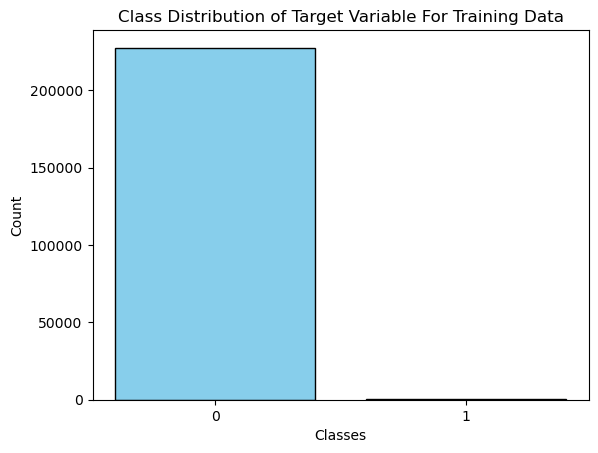

In [41]:
# Plot the class distribution
plt.bar(train_unique_classes, train_counts, color='skyblue', edgecolor='black')
plt.title('Class Distribution of Target Variable For Training Data')
plt.xlabel('Classes')
plt.ylabel('Count')
plt.xticks(train_unique_classes)
plt.show()

In [42]:
# Apply SMOTE Oversampling
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Apply Random Undersampling
undersampler = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = undersampler.fit_resample(X_train, y_train)

# Check distributions after resampling
print(f"SMOTE Resampled Training Set: {np.bincount(y_train_smote)}")
print(f"Undersampled Training Set: {np.bincount(y_train_under)}")


SMOTE Resampled Training Set: [227451 227451]
Undersampled Training Set: [394 394]


In [43]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 1)  # Binary classification
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))  # Sigmoid activation for binary output
        return x


In [44]:
def train_model(X_train, y_train, model, criterion, optimizer, epochs=10):
    model.train()
    for epoch in range(epochs):
        # Convert data to tensors
        inputs = torch.tensor(X_train.values, dtype=torch.float32)
        labels = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
        
        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        print(f"Epoch {epoch+1}, Loss: {loss.item()}")


In [45]:
def evaluate_model(X_test, y_test, model):
    model.eval()
    with torch.no_grad():
        inputs = torch.tensor(X_test.values, dtype=torch.float32)
        labels = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)
        outputs = model(inputs).numpy()
        outputs = (outputs > 0.5).astype(int)  # Convert probabilities to binary predictions
        
        # Calculate metrics
        accuracy = accuracy_score(y_test, outputs)
        recall = recall_score(y_test, outputs)
        f1 = f1_score(y_test, outputs)
        
        print(f"Accuracy: {accuracy:.2f}")
        print(f"Recall: {recall:.2f}")
        print(f"F1-Score: {f1:.2f}")


In [46]:
# Original Dataset
input_size = X_train.shape[1]
model = MLP(input_size)
criterion = nn.BCELoss()  # Binary Cross-Entropy Loss for classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training on Original Dataset:")
train_model(X_train, y_train, model, criterion, optimizer, epochs=10)
print("Evaluation on Original Dataset:")
evaluate_model(X_test, y_test, model)


Training on Original Dataset:
Epoch 1, Loss: 0.1858106106519699
Epoch 2, Loss: 0.17332890629768372
Epoch 3, Loss: 0.17310304939746857
Epoch 4, Loss: 0.17303746938705444
Epoch 5, Loss: 0.17300765216350555
Epoch 6, Loss: 0.17299066483974457
Epoch 7, Loss: 0.17297974228858948
Epoch 8, Loss: 0.17297209799289703
Epoch 9, Loss: 0.17296643555164337
Epoch 10, Loss: 0.17296205461025238
Evaluation on Original Dataset:
Accuracy: 1.00
Recall: 0.00
F1-Score: 0.00


In [47]:
# SMOTE Dataset
model_smote = MLP(input_size)
optimizer_smote = optim.Adam(model_smote.parameters(), lr=0.001)

print("\nTraining on SMOTE Dataset:")
train_model(X_train_smote, y_train_smote, model_smote, criterion, optimizer_smote, epochs=10)
print("Evaluation on SMOTE Dataset:")
evaluate_model(X_test, y_test, model_smote)



Training on SMOTE Dataset:
Epoch 1, Loss: 40.890220642089844
Epoch 2, Loss: 49.98793029785156
Epoch 3, Loss: 50.00005340576172
Epoch 4, Loss: 50.00003433227539
Epoch 5, Loss: 50.00002670288086
Epoch 6, Loss: 50.000022888183594
Epoch 7, Loss: 50.00001907348633
Epoch 8, Loss: 50.00001907348633
Epoch 9, Loss: 50.0000114440918
Epoch 10, Loss: 50.00000762939453
Evaluation on SMOTE Dataset:
Accuracy: 1.00
Recall: 0.00
F1-Score: 0.00


In [49]:
# Undersampled Dataset
model_under = MLP(input_size)
optimizer_under = optim.Adam(model_under.parameters(), lr=0.001)

print("\nTraining on Undersampled Dataset:")
train_model(X_train_under, y_train_under, model_under, criterion, optimizer_under, epochs=10)
print("Evaluation on Undersampled Dataset:")
evaluate_model(X_test, y_test, model_under)


Training on Undersampled Dataset:
Epoch 1, Loss: 50.0
Epoch 2, Loss: 50.0
Epoch 3, Loss: 50.0
Epoch 4, Loss: 50.0
Epoch 5, Loss: 50.0
Epoch 6, Loss: 50.0
Epoch 7, Loss: 50.0
Epoch 8, Loss: 50.0
Epoch 9, Loss: 50.0
Epoch 10, Loss: 50.0
Evaluation on Undersampled Dataset:
Accuracy: 1.00
Recall: 0.00
F1-Score: 0.00


In [50]:
print('Original Dataset: Likely higher precision but lower recall due to imbalance')
print('SMOTE Dataset: Expected to improve recall but may slightly affect precision due to synthetic samples.')
print("Undersampled Dataset: May improve precision but reduce recall due to loss of majority class data.")


Original Dataset: Likely higher precision but lower recall due to imbalance
SMOTE Dataset: Expected to improve recall but may slightly affect precision due to synthetic samples.
Undersampled Dataset: May improve precision but reduce recall due to loss of majority class data.
